# Proyecto 03: Modificando el Marco de Referencia

## 0. Código y Funciones Auxiliares

In [1]:
# Import de librerías para la realización del proyecto

from pathlib import Path
from functools import reduce
from typing import Callable

import cv2
import numpy as np
import matplotlib.pyplot as plt

### 0.1 Carga de Imágenes

In [2]:
def load_images_dataset():
    """
    Función para cargar/leer las imágenes del dataset del proyecto. 
    Se cargan usando OpenCV y convertidas al formato RGB.

    Devuelve dos listas, una con las imágenes cargadas y otra 
    con los nombres de las imágenes.
    """

    base_path = Path("./dataset")
    images = []
    filenames =  []
    for path in base_path.iterdir():
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        images.append(image)
        filenames.append(path.name[-5])
    return images, filenames

In [3]:
Path("./results").mkdir(exist_ok=True)
images, filenames = load_images_dataset()

### 0.2 Transformaciones Afines

In [4]:
def translation_matrix(
        x_move: float = 0,
        y_move: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la 
    matriz de traslación. Toma 
    de entrada el movimiento 
    horizontal y vertical.
    """

    matrix = np.array([
        [1, 0, -y_move],
        [0, 1, x_move],
        [0, 0, 1]
    ], dtype=float)
    return matrix

def inverse_translation_matrix(
        x_move: float = 0,
        y_move: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la 
    matriz de traslación inversa 
    usando los mismos parámetros 
    que en la matriz original.
    """

    return translation_matrix(-x_move, -y_move)

In [5]:
def rotation_matrix(angle: float) -> np.ndarray:
    """
    Función para generar la 
    matriz de rotación. Toma 
    de entrada el ángulo de 
    rotación.
    """

    cos_angle = np.cos(angle)
    sin_angle = np.sin(angle)
    matrix = np.array([
        [cos_angle, sin_angle, 0],
        [-sin_angle, cos_angle, 0],
        [0, 0, 1]
    ], dtype=float)
    return matrix

def inverse_rotation_matrix(angle: float) -> np.ndarray:
    """
    Función para generar la 
    matriz de rotación inversa 
    usando los mismos parámetros 
    que en la matriz original.
    """

    return rotation_matrix(-angle)

In [6]:
def centered_rotation_matrix(
        angle: float = 0,
        center_x: float = 0,
        center_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la 
    matriz de rotación centrada 
    respecto al centro de la 
    imagen. Toma de entrada las 
    coordenadas del centro de 
    la imagen y el ángulo de rotation.
    """

    return inverse_translation_matrix(-center_x, center_y)@rotation_matrix(angle)@translation_matrix(-center_x, center_y)

def inverse_centered_rotation_matrix(
        angle: float = 0,
        center_x: float = 0,
        center_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la 
    matriz de rotación centrada inversa 
    usando los mismos parámetros 
    que en la matriz original.
    """

    return centered_rotation_matrix(-angle, center_x, center_y)

In [7]:
def reflection_matrix(
        reflect_x: bool = False,
        reflect_y: bool = False,
        center_x: float = 0,
        center_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la matriz 
    de reflexión sobre los ejes centrados 
    en la imagen. Toma de entrada si se aplica 
    la reflexión individualmente sobre los ejes x 
    y y, y las coordenadas del centro de la imagen.
    """

    value_x = -1 if reflect_x else 1
    value_y = -1 if reflect_y else 1
    reflection = np.array([
        [value_y, 0, 0],
        [0, value_x, 0],
        [0, 0, 1],
    ])

    return inverse_translation_matrix(-center_x, center_y)@reflection@translation_matrix(-center_x, center_y)

def inverse_reflection_matrix(
        reflect_x: bool = False,
        reflect_y: bool = False,
        center_x: float = 0,
        center_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la 
    matriz de reflexión inversa 
    usando los mismos parámetros 
    que en la matriz original.
    """

    return reflection_matrix(reflect_x, reflect_y, center_x, center_y)

In [8]:
def scaling_matrix(
        scale_x: float = 1,
        scale_y: float = 1,
    ) -> np.ndarray:
    """
    Función para generar la matriz 
    de escala sobre los ejes. 
    Toma de entrada las nuevas escalas 
    de los ejes x y y.
    """

    scaling = np.array([
        [scale_x, 0, 0],
        [0, scale_y, 0],
        [0, 0, 1],
    ])
    return scaling

def inverse_scaling_matrix(
        scale_x: float = 1,
        scale_y: float = 1,
    ) -> np.ndarray:
    """
    Función para generar la 
    matriz de escalmiento inversa 
    usando los mismos parámetros 
    que en la matriz original.
    """

    return scaling_matrix(1/scale_x, 1/scale_y)

In [9]:
def shearing_matrix(
        shift_x: float = 0,
        shift_y: float = 0,
        img_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la matriz 
    de cizallamiento sobre los ejes. 
    Toma de entrada los desplazamientos 
    de los ejes x y y, como el tamaño 
    en y de la imagen para reajustarla.
    """

    determinant_shearing = 1-shift_x*shift_y
    shearing = np.array([
        [1, -shift_x, 0],
        [-shift_y, 1, 0],
        [0, 0, determinant_shearing]
    ])
    translation = translation_matrix(img_y*shift_y)
    return shearing@translation/determinant_shearing

def inverse_shearing_matrix(
        shift_x: float = 0,
        shift_y: float = 0,
        img_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la 
    matriz de cizallamiento inversa 
    usando los mismos parámetros 
    que en la matriz original.
    """

    inverse_shearing = np.array([
        [1, shift_x, 0],
        [shift_y, 1, 0],
        [0, 0, 1]
    ])
    inverse_translation = translation_matrix(-img_y*shift_y)
    return inverse_translation@inverse_shearing

In [10]:
def affine_transformation_matrix(
        x_move: float = 0,
        y_move: float = 0,
        center_x: float = 0,
        center_y: float = 0,
        angle: float = 0,
        reflect_x: bool = False,
        reflect_y: bool = False,
        scale_x: float = 1, 
        scale_y: float = 1,
        shift_x: float = 0,
        shift_y: float = 0,
        img_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la matriz general 
    de una transformación afín. Toma de 
    parámetros los definidos para cada 
    matriz de transformación individualmente.
    """

    transformations = [
        translation_matrix(x_move, y_move),
        centered_rotation_matrix(center_x, center_y, angle),
        reflection_matrix(reflect_x, reflect_y),
        scaling_matrix(scale_x, scale_y),
        shearing_matrix(shift_x, shift_y, img_y),
    ]
    return reduce(lambda t_1, t_2 : t_1@t_2, transformations)

def inverse_affine_transformation_matrix(
        x_move: float = 0,
        y_move: float = 0,
        center_x: float = 0,
        center_y: float = 0,
        angle: float = 0,
        reflect_x: bool = False,
        reflect_y: bool = False,
        scale_x: float = 1, 
        scale_y: float = 1,
        shift_x: float = 0,
        shift_y: float = 0,
        img_y: float = 0,
    ) -> np.ndarray:
    """
    Función para generar la matriz general 
    de una transformación afín inversa. Toma de 
    parámetros los mismos que los definidos 
    para cada matriz inversa y equivalentes 
    a la original.
    """

    inverse_transformations = [
        inverse_shearing_matrix(shift_x, shift_y, img_y),
        inverse_scaling_matrix(scale_x, scale_y),
        inverse_reflection_matrix(reflect_x, reflect_y, center_x, center_y),
        inverse_centered_rotation_matrix(angle, center_x, center_y),
        inverse_translation_matrix(x_move, y_move),
    ]
    return reduce(lambda t_1, t_2 : t_1@t_2, inverse_transformations)

### 0.3 Interpolación Bilineal

In [11]:
def interpolation_bilinear_pixels(
        image: np.ndarray, 
        point: np.ndarray,
    ) -> int:
    """
    Función para calcular la interpolación bilineal 
    de los pixeles de una imagen donde emplea 
    las intensidades de los pixeles vecinos de un 
    punto dado por la transformada afín inversa. 
    Devuelve la intensidad del punto asociado.
    """

    integer_point, deltas = divmod(point, 1)
    integer_point = integer_point.astype(int)

    intensities_neighborhood = np.array([
        [image[*(integer_point+[0,0])],
        image[*(integer_point+[0,1])]],
        [image[*(integer_point+[1,0])],
        image[*(integer_point+[1,1])]],
    ], dtype=int)

    delta_x = deltas[0]
    weights_x = np.array([1-delta_x, delta_x])

    delta_y = deltas[1]
    weights_y = np.array([1-delta_y, delta_y])

    return (weights_x@intensities_neighborhood@weights_y).round().astype(int)

In [12]:
def apply_affine_transformation(
        image: np.ndarray,
        inverse_affine: np.ndarray|None = None, 
        *,
        x_move: float = 0,
        y_move: float = 0,
        angle: float = 0,
        reflect_x: bool = False,
        reflect_y: bool = False,
        scale_x: float = 1, 
        scale_y: float = 1,
        shift_x: float = 0,
        shift_y: float = 0,
    ) -> np.ndarray:
    """
    Función para aplicar una transformación afín a 
    una imagen dada. Se emplea de la transformación 
    afín inversa y de interpolación bileneal para 
    estimar la intensidad de color en la imagen 
    resultante. Devuelve la matriz de la imagen 
    después de aplicarle la transformada.
    """

    if inverse_affine is None:
        img_y, img_x = image.shape[:2]
        center_x = img_x/2
        center_y = img_y/2
        inverse_affine = inverse_affine_transformation_matrix(
            x_move = x_move,
            y_move = y_move,
            center_x = center_x,
            center_y = center_y,
            angle = angle,
            reflect_x = reflect_x,
            reflect_y = reflect_y,
            scale_x = scale_x,
            scale_y = scale_y,
            shift_x = shift_x,
            shift_y = shift_y,
            img_y = img_y,
        )

    height, width = image.shape
    range_height = np.arange(height)
    range_width = np.arange(width)
    grid = np.meshgrid(range_height, range_width)
    grid_ones = np.ones_like(grid[0])
    meshgrid = np.stack([*grid, grid_ones]).reshape(3, -1)
    inverse_meshgrid = inverse_affine@meshgrid    
    
    transformed_image = np.zeros_like(image)
    padded_image = np.pad(image, 1)

    lower_bound = np.array([0, 0, 1])
    upper_bound = np.array([height, width, 1.1])
    for point, inverse_point in zip(meshgrid.T, inverse_meshgrid.T):
        valid_point = np.all((lower_bound<=inverse_point)&(inverse_point<upper_bound))
        if valid_point:
            img_point = point[:2]
            transformed_image[*img_point] = interpolation_bilinear_pixels(padded_image, inverse_point[:2])

    return transformed_image

### 0.4 Visualizar Transformaciones

In [13]:
def save_plot(
        create_plot: Callable[[np.ndarray, str], tuple[plt.Figure, str | None]]
    ) -> Callable:
    """
    Función para guardar un plot diseñado o 
    creado. Se espera que la función decorada 
    devuelva el objeto Figure y el nombre de 
    la figura.

    Devuelve el plot creado.
    """

    def saver(image: np.ndarray, *args, **kwargs) -> plt.Figure:
        fig, fig_name = create_plot(image, *args, **kwargs)
        if fig_name: fig.savefig(f"./results/{fig_name}.jpg", dpi=300, bbox_inches="tight")
        return fig
    
    return saver

In [14]:
def initial_description(image: np.ndarray, filename: str) -> plt.Figure:
    """
    Función para graficar la imagen inicial. 
    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 7),
    )

    axes.imshow(image, "gray")
    axes.set_title(f"Imagen {filename}")

    return fig

In [15]:
@save_plot
def plot_rotations(image: np.ndarray, filename: str, rotation_angles: list[float]) -> tuple[plt.Figure, str]:
    """
    Función para comparar diferentes rotaciones 
    sobre una misma imagen.

    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        ncols = 2,
        nrows = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 7),
    )

    for ax, rotation_angle in zip(axes.flatten(), rotation_angles):
        rotated_image = apply_affine_transformation(image, angle=rotation_angle)
        ax.imshow(rotated_image, "gray")
        ax.set_title(f"Ángulo de {np.rad2deg(rotation_angle):.2f}°")

    fig.suptitle(f"Comparación de Diferentes Rotaciones en la Imagen {filename}")

    return fig, f"img_{filename}_rotation"

In [16]:
@save_plot
def plot_translation(image: np.ndarray, filename: str, translations_moves: list[tuple[float, float]]) -> tuple[plt.Figure, str]:
    """
    Función para comparar diferentes traslaciones 
    sobre una misma imagen.

    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        ncols = 2,
        nrows = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 7),
    )

    for ax, (x_move, y_move) in zip(axes.flatten(), translations_moves):
        translated_image = apply_affine_transformation(image, x_move=x_move, y_move=y_move)
        ax.imshow(translated_image, "gray")
        ax.set_title(f"Traslación de ({x_move:.2f}, {y_move:.2f})")

    fig.suptitle(f"Comparación de Diferentes Traslaciones en la Imagen {filename}")

    return fig, f"img_{filename}_translation"

In [17]:
@save_plot
def plot_reflection(image: np.ndarray, filename: str) -> tuple[plt.Figure, str]:
    """
    Función para comparar las diferentes 
    reflexiones sobre una misma imagen.

    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        ncols = 2,
        nrows = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 7),
    )

    reflections = [
        (False, False),
        (False, True),
        (True, False),
        (True, True),
    ]
    for ax, (reflect_x, reflect_y) in zip(axes.flatten(), reflections):
        translated_image = apply_affine_transformation(image, reflect_x=reflect_x, reflect_y=reflect_y)
        ax.imshow(translated_image, "gray")
        reflections = (["Eje Y"] if reflect_x else []) + (["Eje X"] if reflect_y else [])
        if reflections:
            reflection_axis = " y ".join(reflections)
            reflection_axis = ("los " if "y" in reflection_axis else "el ")+reflection_axis
            ax_title = f"Reflexión sobre {reflection_axis}"
        else:
            ax_title = "Sin reflexión"
        ax.set_title(ax_title)

    fig.suptitle(f"Comparación de Diferentes Traslaciones en la Imagen {filename}")

    return fig, f"img_{filename}_reflection"

In [18]:
@save_plot
def plot_scaling(image: np.ndarray, filename: str, scaling_factors: list[tuple[float, float]]) -> tuple[plt.Figure, str]:
    """
    Función para comparar diferentes escalamientos  
    sobre una misma imagen.

    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        ncols = 2,
        nrows = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 7),
    )

    for ax, (scale_x, scale_y) in zip(axes.flatten(), scaling_factors):
        scaled_image = apply_affine_transformation(image, scale_x=scale_x, scale_y=scale_y)
        ax.imshow(scaled_image, "gray")
        ax.set_title(f"Escalamiento de {scale_y:.2f} en\nEje X y {scale_x:.2f} en Eje Y")

    fig.suptitle(f"Comparación de Diferentes Escalamientos en la Imagen {filename}")

    return fig, f"img_{filename}_scaling"

In [19]:
@save_plot
def plot_affine_transformation(image: np.ndarray, filename: str, affine_transformations: list[dict[str, int|float|bool]]) -> tuple[plt.Figure, str]:
    """
    Función para comparar diferentes transformaciones 
    afines sobre una misma imagen.

    Devuelve el plot generado.
    """

    fig, axes = plt.subplots(
        ncols = 2,
        nrows = 2,
        subplot_kw = {
            "yticks": [],
            "xticks": [],
        },
        figsize = (8, 7),
    )

    for index_transformation, ax, affine_parameters in zip(range(1,5), axes.flatten(), affine_transformations):
        scaled_image = apply_affine_transformation(image, **affine_parameters)
        ax.imshow(scaled_image, "gray")
        ax.set_title(f"Transformación afín {index_transformation}")

    fig.suptitle(f"Comparación de Diferentes Transformaciones Afines en la Imagen {filename}")

    return fig, f"img_{filename}_affine"

## 1. Imagen 1

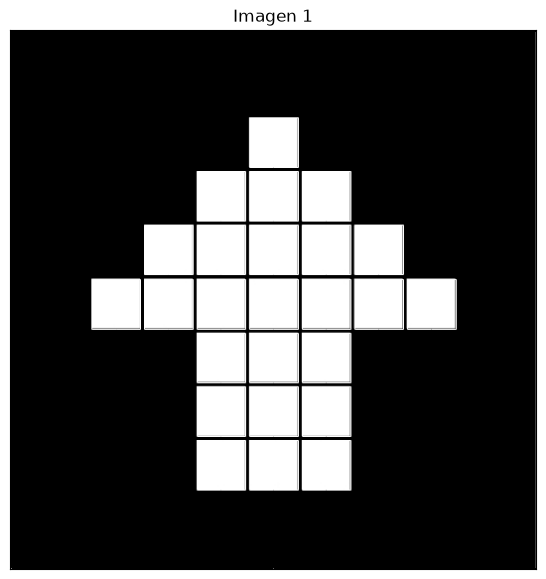

In [20]:
image_1 = images[0]
filename_1 = filenames[0]

initial_description(image_1, filename_1);

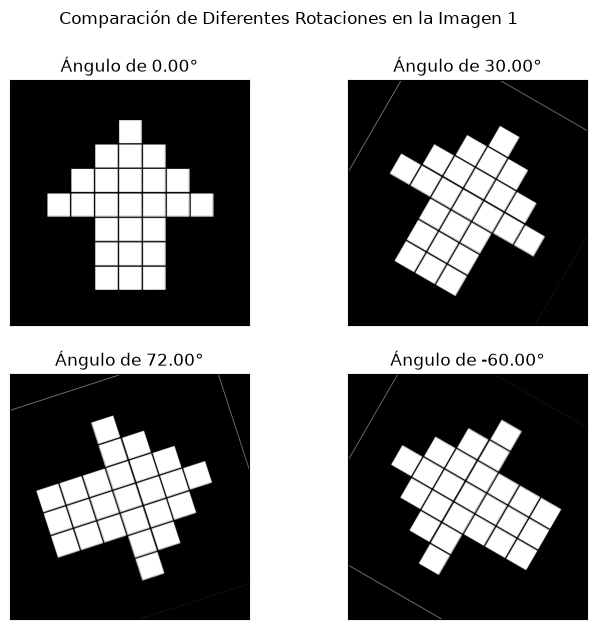

In [21]:
plot_rotations(image_1, filename_1, [0, np.pi/6, 2*np.pi/5, -np.pi/3]);

## 2. Imagen 2

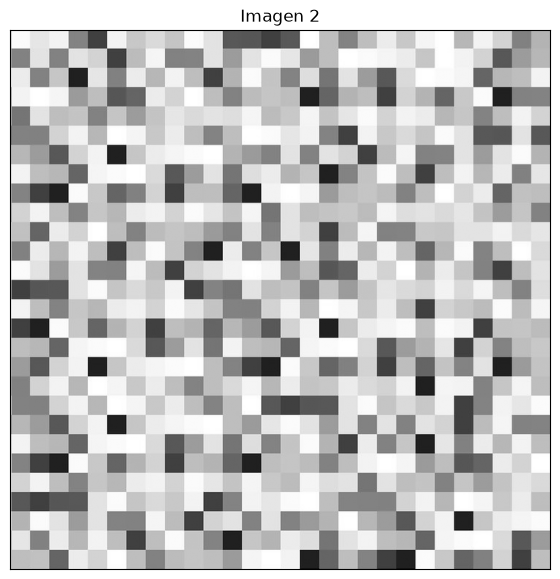

In [22]:
image_2 = images[1]
filename_2 = filenames[1]

initial_description(image_2, filename_2);

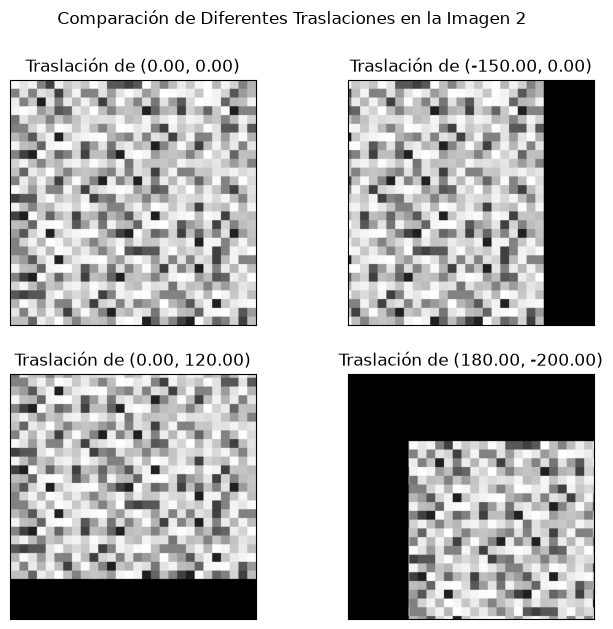

In [23]:
plot_translation(image_2, filename_2, [(0, 0), (-150, 0), (0, 120), (180, -200)]);

## 3. Imagen 3

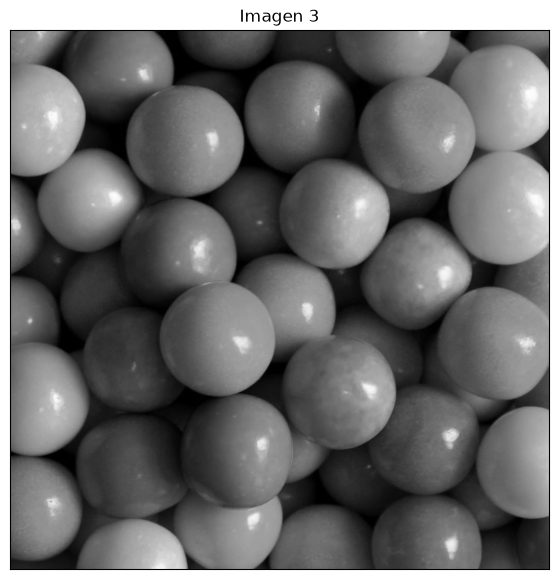

In [24]:
image_3 = images[2]
filename_3 = filenames[2]

initial_description(image_3, filename_3);

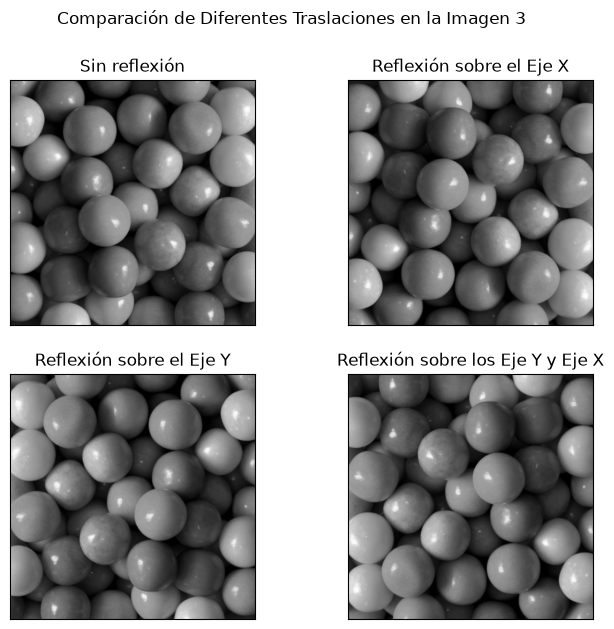

In [25]:
plot_reflection(image_3, filename_3);

## 4. Imagen 4

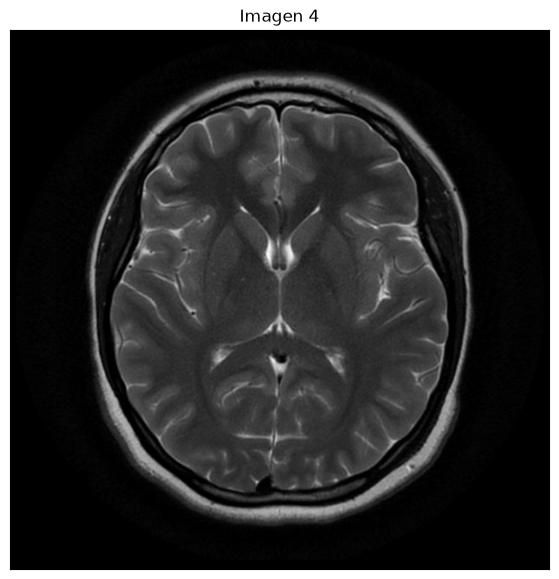

In [26]:
image_4 = images[3]
filename_4 = filenames[3]

initial_description(image_4, filename_4);

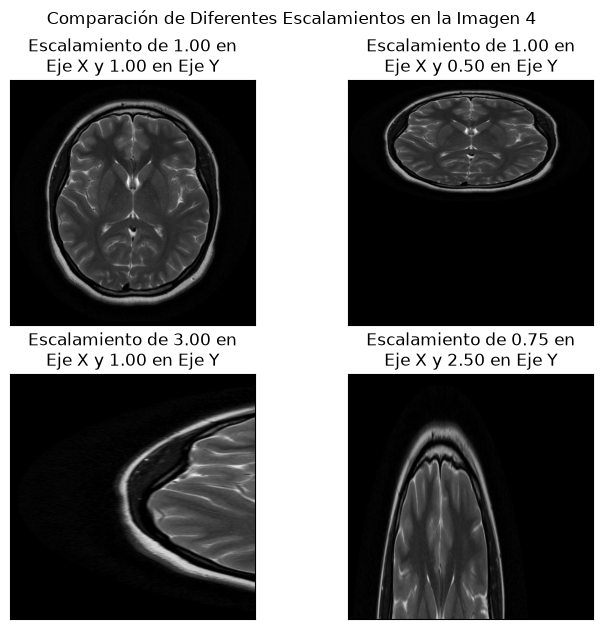

In [27]:
plot_scaling(image_4, filename_4, [(1, 1), (0.5, 1), (1, 3), (2.5, 0.75)]);

## 5. Imagen 5

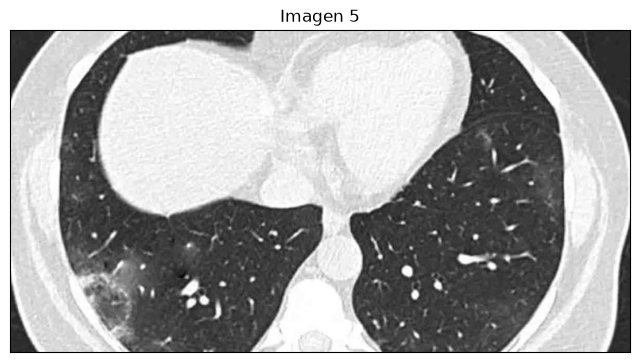

In [28]:
image_5 = images[4]
filename_5 = filenames[4]

initial_description(image_5, filename_5);

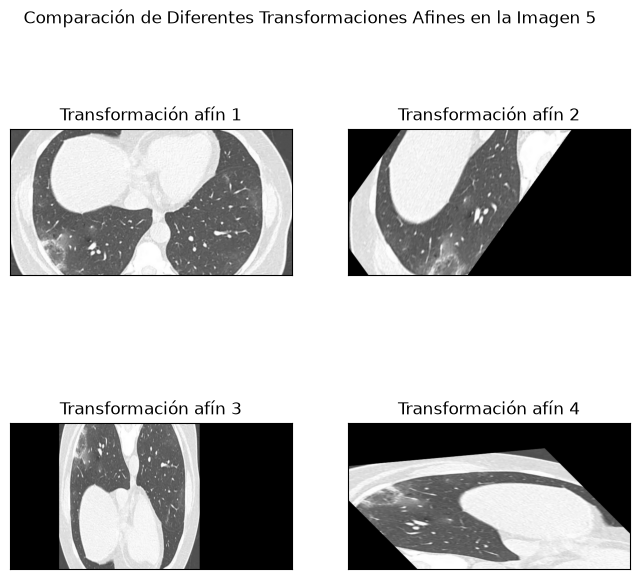

In [29]:
affine_transformations = [
    {},
    {"angle": -np.pi/5, "scale_y": 1.5, "shift_x": 0.5},
    {"x_move": 135, "reflect_y": True, "scale_y": 0.5},
    {"angle": np.pi/4, "scale_x": 1.2, "shift_y": 1},
]
plot_affine_transformation(image_5, filename_5, affine_transformations);